# SVM Baseline V7 — Sinhala Hate Speech Detection Under Code-Mixing Noise

**Project:** Robustness of SLM-Based Sinhala Hate Speech Detection Under Realistic Text Noise

---

## What this notebook does

This notebook implements the **SVM traditional ML baseline**. The SVM is trained on **code-mixed** Sinhala social-media text and serves as a language-independent, noise-tolerant reference floor against which encoder-based and SLM-based models will later be compared.

## Why SVM with character n-grams?

Sinhala code-mixed text can contain Sinhala and English tokens or phrases within the same post. Character n-gram TF-IDF provides a language-agnostic representation that can capture recurring sub-string patterns across Sinhala and English/code-mixed forms without requiring a manually defined bilingual vocabulary.

## Experimental design

Two separate SVM models are trained, one per code-mixing severity:

```
         ┌──────────────┐      ┌──────────────┐
TRAIN →  │  SVM-Light   │      │  SVM-Heavy   │
         └──────┬───────┘      └──────┬───────┘
                │                     │
        ┌───────┴───────┐     ┌───────┴───────┐
        ▼               ▼     ▼               ▼
   Light-Test      Heavy-Test Light-Test  Heavy-Test
```

All four evaluation combinations are reported, enabling:
- **Same-severity results** (in-domain performance)
- **Cross-severity results** (generalisation to different noise levels)
- **Degradation analysis** per fixed model across noise severities

## Scope of this notebook

- Code-mixing noise only (light + heavy)
- No clean SOLD data (will be added when available)
- No other noise types (code-mixing, misspelling, abbreviation — to be added with their datasets)
- Primary SVM representation: **character TF-IDF (1–5) only**


> **Current experiment:** CodeMix Light + Heavy. This notebook is a CodeMix adaptation of the refined SVM baseline and keeps the same model-selection and evaluation methodology used for the transliteration experiment.


## 2. Imports and Environment Setup

All required packages come pre-installed in Google Colab. `joblib` is used for model persistence, `pathlib` for portable path handling.


In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from datetime import datetime

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    accuracy_score,
)
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports OK")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Imports OK
NumPy: 2.0.2
Pandas: 2.2.2


## 3. Configuration

Edit the two paths below to match your Google Drive layout.

Expected Drive layout:
```
outputs/
├── train/
│   ├── codemix_light.jsonl
│   └── codemix_heavy.jsonl
└── test/
    ├── codemix_light.jsonl
    └── codemix_heavy.jsonl
```


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
OUTPUTS_ROOT = "/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs"

# Current experiment: CodeMix Light / Heavy
NOISE_TYPE   = "codemix"
SEVERITIES   = ["light", "heavy"]

# Keep CodeMix artifacts separate from the CodeMix experiment.
OUT_DIR = (
    "/content/drive/MyDrive/"
    "Sinhala-Noisy-Hatespeech-Data/"
    "svm_artifacts/codemix"
)

TEXT_COL     = "noisy_text"
LABEL_COL    = "label"
LABEL_NAMES  = ["not_offensive", "offensive"]

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

# File paths are derived from NOISE_TYPE — do not edit below this line.
TRAIN_FILES = {
    sev: f"{OUTPUTS_ROOT}/train/{NOISE_TYPE}_{sev}.jsonl"
    for sev in SEVERITIES
}
TEST_FILES = {
    sev: f"{OUTPUTS_ROOT}/test/{NOISE_TYPE}_{sev}.jsonl"
    for sev in SEVERITIES
}

print("NOISE_TYPE   :", NOISE_TYPE)
print("OUTPUTS_ROOT :", OUTPUTS_ROOT)
print("OUT_DIR      :", OUT_DIR)
print()

for sev in SEVERITIES:
    tp = Path(TRAIN_FILES[sev])
    ep = Path(TEST_FILES[sev])
    print(f"[{sev}] train={tp}  exists={tp.exists()} | test={ep}  exists={ep.exists()}")
    if not tp.exists() or not ep.exists():
        raise FileNotFoundError(
            f"Missing CodeMix dataset for severity '{sev}'. "
            f"Expected:\n  train: {tp}\n  test:  {ep}"
        )


NOISE_TYPE   : codemix
OUTPUTS_ROOT : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs
OUT_DIR      : /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix

[light] train=/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/codemix_light.jsonl  exists=True | test=/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/codemix_light.jsonl  exists=True
[heavy] train=/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/train/codemix_heavy.jsonl  exists=True | test=/content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/outputs/test/codemix_heavy.jsonl  exists=True


## 4. Dataset Loading

Data is stored as newline-delimited JSON (JSONL). Each record has at minimum:

- `source_id` — original SOLD post identifier
- `noisy_text` — code-mixed version of the post used as the model input
- `label` — 0 = not offensive, 1 = offensive (unchanged from clean SOLD)

The `data` dictionary mirrors the JSONL directory structure:

`data[severity][split]` → pandas DataFrame.

The same loading and preprocessing logic is used for both CodeMix severity levels so that the SVM comparison remains consistent.


In [4]:
def load_jsonl(path: str) -> pd.DataFrame:
    """Load a JSONL file into a DataFrame, skipping blank lines."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)


data = {}
for sev in SEVERITIES:
    df_train = load_jsonl(TRAIN_FILES[sev])
    df_test  = load_jsonl(TEST_FILES[sev])

    # Ensure correct types
    df_train[TEXT_COL]  = df_train[TEXT_COL].astype(str)
    df_test[TEXT_COL]   = df_test[TEXT_COL].astype(str)
    df_train[LABEL_COL] = df_train[LABEL_COL].astype(int)
    df_test[LABEL_COL]  = df_test[LABEL_COL].astype(int)

    data[sev] = {"train": df_train.reset_index(drop=True),
                 "test":  df_test.reset_index(drop=True)}

    print(f"[{sev}] train: {len(df_train):,} rows | test: {len(df_test):,} rows")


[light] train: 7,500 rows | test: 2,500 rows
[heavy] train: 7,500 rows | test: 2,500 rows


## 5. Dataset Validation

Before training, verify every split for:
- Required column presence
- Missing values
- Class distribution and balance
- Duplicate texts (informational only — not removed, as duplicates may be genuine)


In [5]:
def validate_dataset(df: pd.DataFrame, severity: str, split: str) -> None:
    """Validate a single train/test DataFrame and print a structured summary."""
    print("=" * 70)
    print(f"  {severity.upper()} — {split.upper()}")
    print("=" * 70)

    required_columns = [TEXT_COL, LABEL_COL]
    for col in required_columns:
        assert col in df.columns, (
            f"Missing required column '{col}' in {severity}/{split}. "
            f"Available columns: {list(df.columns)}"
        )

    print(f"Samples            : {len(df):,}")
    print(f"Columns available  : {list(df.columns)}")

    missing = df[required_columns].isnull().sum()
    print(f"\nMissing values:")
    print(missing.to_string())

    dist = df[LABEL_COL].value_counts().rename({0: "not_offensive", 1: "offensive"})
    prop = df[LABEL_COL].value_counts(normalize=True).rename({0: "not_offensive", 1: "offensive"})
    print(f"\nClass distribution:")
    print(dist.to_string())
    print(f"\nClass proportions:")
    print(prop.round(4).to_string())

    dups = df[TEXT_COL].duplicated().sum()
    print(f"\nDuplicate texts    : {dups:,}")
    print(f"Unique labels      : {sorted(df[LABEL_COL].unique())}")
    print()


for sev in SEVERITIES:
    for split in ("train", "test"):
        validate_dataset(data[sev][split], sev, split)


  LIGHT — TRAIN
Samples            : 7,500
Columns available  : ['source_id', 'split', 'condition', 'severity', 'original_text', 'noisy_text', 'label', 'realised_noise_rate', 'generator_version', 'n_substitutions']

Missing values:
noisy_text    0
label         0

Class distribution:
label
not_offensive    4324
offensive        3176

Class proportions:
label
not_offensive    0.5765
offensive        0.4235

Duplicate texts    : 0
Unique labels      : [np.int64(0), np.int64(1)]

  LIGHT — TEST
Samples            : 2,500
Columns available  : ['source_id', 'split', 'condition', 'severity', 'original_text', 'noisy_text', 'label', 'realised_noise_rate', 'generator_version', 'n_substitutions']

Missing values:
noisy_text    0
label         0

Class distribution:
label
not_offensive    1485
offensive        1015

Class proportions:
label
not_offensive    0.594
offensive        0.406

Duplicate texts    : 0
Unique labels      : [np.int64(0), np.int64(1)]

  HEAVY — TRAIN
Samples            : 7,

## 5.1. Cross-Severity Test-Set Alignment

The light and heavy code-mixing test sets are intended to represent the **same underlying SOLD posts at different code-mixing severities**. The `source_id` field is therefore checked explicitly before cross-severity degradation analysis.

This validation checks:
- every Light test `source_id` is also present in Heavy test;
- every Heavy test `source_id` is also present in Light test; and
- the class label is identical for the two severity versions of each source post.

If this check fails, the notebook stops rather than making a controlled-severity degradation claim from unmatched test samples.


In [6]:
def validate_cross_severity_alignment() -> pd.DataFrame:
    """Verify that CodeMix Light and Heavy test sets are paired versions of the same posts."""
    light = data["light"]["test"]
    heavy = data["heavy"]["test"]

    if "source_id" not in light.columns or "source_id" not in heavy.columns:
        raise AssertionError(
            "Cross-severity evaluation requires 'source_id' in both CodeMix Light and Heavy test sets."
        )

    light_ids = set(light["source_id"].astype(str))
    heavy_ids = set(heavy["source_id"].astype(str))

    only_light = light_ids - heavy_ids
    only_heavy = heavy_ids - light_ids

    print("CodeMix Light test unique source IDs :", len(light_ids))
    print("CodeMix Heavy test unique source IDs :", len(heavy_ids))
    print("Common source IDs                   :", len(light_ids & heavy_ids))
    print("Only in Light                       :", len(only_light))
    print("Only in Heavy                       :", len(only_heavy))

    if only_light or only_heavy:
        raise AssertionError(
            "CodeMix Light and Heavy test sets are not aligned by source_id. "
            "Cross-severity comparison cannot be treated as a paired comparison."
        )

    light_labels = light[["source_id", LABEL_COL]].copy()
    heavy_labels = heavy[["source_id", LABEL_COL]].copy()
    light_labels["source_id"] = light_labels["source_id"].astype(str)
    heavy_labels["source_id"] = heavy_labels["source_id"].astype(str)

    aligned = light_labels.merge(
        heavy_labels,
        on="source_id",
        how="inner",
        suffixes=("_light", "_heavy"),
        validate="one_to_one",
    )

    label_mismatches = aligned[
        aligned[f"{LABEL_COL}_light"] != aligned[f"{LABEL_COL}_heavy"]
    ]

    print("Aligned test posts                   :", len(aligned))
    print("Label mismatches                     :", len(label_mismatches))

    if len(label_mismatches) > 0:
        raise AssertionError(
            "Labels differ between Light and Heavy versions of the same CodeMix source posts."
        )

    print("\n✓ CodeMix Light and Heavy test sets are aligned by source_id.")
    print("✓ Labels are consistent across CodeMix severity versions.")
    return aligned


aligned_test_ids = validate_cross_severity_alignment()


CodeMix Light test unique source IDs : 2500
CodeMix Heavy test unique source IDs : 2500
Common source IDs                   : 2500
Only in Light                       : 0
Only in Heavy                       : 0
Aligned test posts                   : 2500
Label mismatches                     : 0

✓ CodeMix Light and Heavy test sets are aligned by source_id.
✓ Labels are consistent across CodeMix severity versions.


## 5.2. Train/Test Source-ID Leakage Check

Before training, verify that no underlying `source_id` appears in any training split and any testing split. This is checked across all Light/Heavy train-test combinations because the experiment includes cross-severity evaluation.

The expected overlap for every combination is **zero**. If an overlap is found, the notebook stops because the same underlying source post may have appeared during training and testing.


In [7]:
def validate_train_test_source_separation() -> None:
    """Check for source-ID overlap between every training and testing condition."""
    print("\n" + "=" * 70)
    print("  TRAIN/TEST SOURCE-ID LEAKAGE CHECK")
    print("=" * 70)

    for train_sev in SEVERITIES:
        train_df = data[train_sev]["train"]

        if "source_id" not in train_df.columns:
            raise AssertionError(
                f"Missing 'source_id' in {train_sev} training data. "
                "Cannot verify train/test source separation."
            )

        train_ids = set(train_df["source_id"].astype(str))

        for test_sev in SEVERITIES:
            test_df = data[test_sev]["test"]

            if "source_id" not in test_df.columns:
                raise AssertionError(
                    f"Missing 'source_id' in {test_sev} test data. "
                    "Cannot verify train/test source separation."
                )

            test_ids = set(test_df["source_id"].astype(str))
            overlap = train_ids & test_ids

            print(
                f"{train_sev.upper()} train ∩ {test_sev.upper()} test : "
                f"{len(overlap):,} overlapping source IDs"
            )

            if overlap:
                examples = sorted(overlap)[:10]
                raise AssertionError(
                    f"Source-ID leakage detected between {train_sev} train and "
                    f"{test_sev} test. Example IDs: {examples}"
                )

    print("\n✓ No train/test source-ID overlap detected across any severity combination.")


validate_train_test_source_separation()



  TRAIN/TEST SOURCE-ID LEAKAGE CHECK
LIGHT train ∩ LIGHT test : 0 overlapping source IDs
LIGHT train ∩ HEAVY test : 0 overlapping source IDs
HEAVY train ∩ LIGHT test : 0 overlapping source IDs
HEAVY train ∩ HEAVY test : 0 overlapping source IDs

✓ No train/test source-ID overlap detected across any severity combination.


## 6. Class Distribution Analysis

The SOLD dataset has a mild class imbalance (~41 % offensive). This motivates:
1. Macro-F1 as the primary metric (treats both classes equally).
2. `class_weight="balanced"` inside SVM to avoid the model defaulting to the majority class.


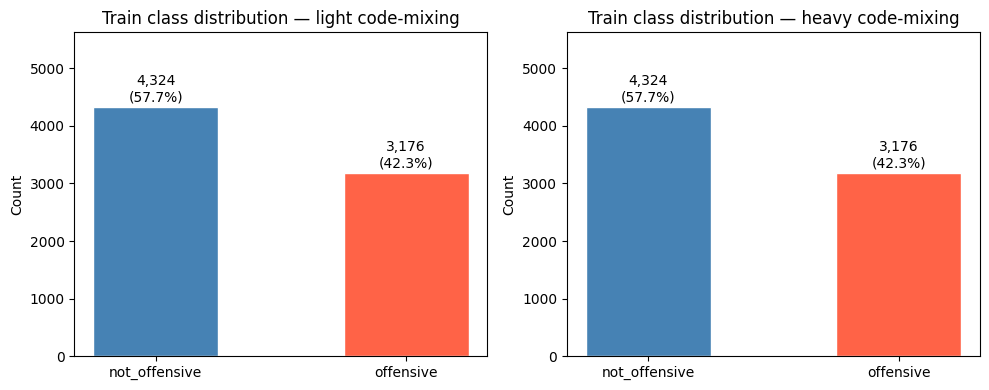

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, sev in zip(axes, SEVERITIES):
    train_df = data[sev]["train"]
    counts = train_df[LABEL_COL].value_counts().rename({0: "not_offensive", 1: "offensive"})
    bars = ax.bar(counts.index, counts.values,
                  color=["steelblue", "tomato"], edgecolor="white", width=0.5)
    ax.set_title(f"Train class distribution — {sev} code-mixing", fontsize=12)
    ax.set_ylabel("Count")
    ax.set_ylim(0, len(train_df) * 0.75)
    for bar, (label, val) in zip(bars, counts.items()):
        pct = 100 * val / len(train_df)
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 50,
                f"{val:,}\n({pct:.1f}%)",
                ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. SVM Feature Representation

**Primary representation: character-level TF-IDF with 1–5 character n-grams.**

| Parameter | Value | Rationale |
|---|---|---|
| `analyzer` | `char_wb` | Character n-grams constrained to word boundaries |
| `ngram_range` | `(1, 5)` | Captures single chars up to 5-char patterns; aligns with proposal |
| `min_df` | `2` | Filters hapax n-grams, reducing noise from one-off code-mixing variants |
| `sublinear_tf` | `True` | Log-scales raw TF, preventing high-frequency n-grams from dominating |

**Important:** The vectorizer is placed *inside* the scikit-learn `Pipeline` and is
therefore fitted **within each cross-validation training fold**. This prevents any test-set
information from leaking into the feature vocabulary or IDF statistics.


## 8. SVM Pipeline

The `Pipeline` object chains TF-IDF and SVM into a single estimator.
This ensures the vectorizer is refitted from scratch on each cross-validation
training fold — a critical requirement for valid hyperparameter selection.

```
Raw text
   │
   ▼
TfidfVectorizer(analyzer="char_wb", ngram_range=(1,5), ...)
   │
   ▼
SVC(class_weight="balanced", ...)
   │
   ▼
Prediction (0 = not_offensive, 1 = offensive)
```


**Kernel selection:** The SVM kernel is selected by `GridSearchCV`; both `linear` and `rbf` are evaluated together with the C values in the grid.

In [9]:
def build_svm_pipeline() -> Pipeline:
    """
    Build the primary SVM pipeline: character TF-IDF (1-5) -> SVC.

    The pipeline is the object passed to GridSearchCV so that the TF-IDF
    vocabulary and IDF statistics are learned *within* each CV fold, never
    on the test set.
    """
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(1, 5),
            min_df=2,
            sublinear_tf=True,
        )),
        ("svm", SVC(
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])


print("SVM pipeline defined:")
print(build_svm_pipeline())


SVM pipeline defined:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', min_df=2,
                                 ngram_range=(1, 5), sublinear_tf=True)),
                ('svm', SVC(class_weight='balanced', random_state=42))])


## 9. Hyperparameter Tuning

**Search strategy:** `GridSearchCV` over a small, principled grid.

**Parameters tuned:**

| Parameter | Values | Notes |
|---|---|---|
| `svm__kernel` | `linear`, `rbf` | Linear is efficient for sparse TF-IDF; RBF can capture nonlinear decision boundaries |
| `svm__C` | `0.1, 1, 3, 10` | Regularisation parameter; larger values penalise training errors more strongly |

**CV setup:**
- 5-fold stratified cross-validation
- Scored on **macro-F1** (equal weight to both classes)
- The complete TF-IDF + SVM pipeline is passed to `GridSearchCV`
- Test data is never seen during hyperparameter tuning

**Computational note:** 2 kernels × 4 C values × 5 folds = 40 SVM fits per severity.
This is intentionally more expensive than the linear-only version because kernel type is
now tuned as specified in the proposal.


### Computational note
The primary SVM search uses the linear kernel only. This keeps the character-level TF-IDF + SVM methodology while avoiding the substantially more expensive RBF search. Five-fold stratified cross-validation and the proposal-aligned 1–5 character n-grams are retained. Training scores are not stored because they are not required for the main evaluation.


In [10]:
SVM_PARAM_GRID = {
    "svm__kernel": ["linear", "rbf"],
    "svm__C":      [0.1, 1, 3, 10],
}


## 10 & 11. Train Light and Heavy SVM Models

One SVM is trained per code-mixing severity.

For each severity:
1. Load the training split (`noisy_text`, `label`).
2. Build the Pipeline.
3. Run 5-fold stratified `GridSearchCV` optimising macro-F1.
4. Record best params and best CV macro-F1.
5. Return the fitted best pipeline (TF-IDF + SVM together).

The test set is **not touched** at this stage.


In [11]:
def train_svm_for_severity(severity: str) -> dict:
    """
    Train SVM on the given severity's training data via GridSearchCV.

    Returns an artifact dict containing the fitted pipeline, best params,
    best CV macro-F1, and training metadata.
    """
    print(f"\n{'='*70}")
    print(f"  Training SVM — {severity.upper()} code-mixing noise")
    print(f"{'='*70}")

    train_df = data[severity]["train"]
    X_train  = train_df[TEXT_COL].values
    y_train  = train_df[LABEL_COL].values

    n_pos = (y_train == 1).sum()
    n_neg = (y_train == 0).sum()
    print(f"Training samples : {len(y_train):,}  "
          f"(not_offensive={n_neg}, offensive={n_pos})")

    pipeline = build_svm_pipeline()

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=SVM_PARAM_GRID,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)

    best_params  = search.best_params_
    best_cv_f1   = search.best_score_
    best_pipeline = search.best_estimator_

    print(f"\nBest params  : {best_params}")
    print(f"Best CV macro-F1 : {best_cv_f1:.4f}")

    artifact = {
        "severity":      severity,
        "pipeline":      best_pipeline,   # complete TF-IDF + SVM pipeline
        "best_params":   best_params,
        "cv_macro_f1":   best_cv_f1,
        "train_size":    len(y_train),
        "timestamp":     datetime.now().isoformat(timespec="seconds"),
    }
    return artifact


# ── Run training for both severities ─────────────────────────────────────────
trained_models = {}
for sev in SEVERITIES:
    trained_models[sev] = train_svm_for_severity(sev)

print("\nAll models trained.")
for sev, art in trained_models.items():
    print(f"  [{sev}] best_params={art['best_params']}  cv_macro_f1={art['cv_macro_f1']:.4f}")



  Training SVM — LIGHT code-mixing noise
Training samples : 7,500  (not_offensive=4324, offensive=3176)
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best params  : {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV macro-F1 : 0.8053

  Training SVM — HEAVY code-mixing noise
Training samples : 7,500  (not_offensive=4324, offensive=3176)
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best params  : {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV macro-F1 : 0.8040

All models trained.
  [light] best_params={'svm__C': 10, 'svm__kernel': 'rbf'}  cv_macro_f1=0.8053
  [heavy] best_params={'svm__C': 10, 'svm__kernel': 'rbf'}  cv_macro_f1=0.8040


## 12 & 13. Evaluation — Same-Severity and Cross-Severity

A single `evaluate_model` function handles all four train/test combinations.
This avoids duplicated evaluation code and ensures consistent metric reporting.

**Four evaluation conditions:**

| Model trained on | Evaluated on | Type |
|---|---|---|
| Light | Light test | Same-severity |
| Light | Heavy test | Cross-severity |
| Heavy | Heavy test | Same-severity |
| Heavy | Light test | Cross-severity |

**Important methodological note:** The cross-severity evaluation uses the *already-trained*
pipeline without any retraining. This measures how well a model trained on one noise level
generalises to a different noise level of the same vector.

**Metrics reported**:
- Accuracy
- Macro-F1 (primary)
- Weighted-F1
- Per-class precision, recall, F1 for both `not_offensive` and `offensive`
- Offensive-class recall highlighted separately
- Confusion matrix


In [12]:
def evaluate_model(artifact: dict, test_severity: str) -> tuple:
    """Evaluate a fitted SVM pipeline on one test severity without retraining."""
    train_sev = artifact["severity"]
    pipeline = artifact["pipeline"]

    test_df = data[test_severity]["test"].copy().reset_index(drop=True)
    X_test = test_df[TEXT_COL].values
    y_true = test_df[LABEL_COL].values

    y_pred = pipeline.predict(X_test)

    # SVC exposes decision_function for both linear and RBF kernels.
    # The score is signed relative to the decision boundary and is useful for error analysis.
    decision_scores = pipeline.decision_function(X_test)

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    prec, rec, f1_per, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # Baselines are determined from TRAINING labels only.
    train_labels = data[train_sev]["train"][LABEL_COL].astype(int).values
    classes = sorted(np.unique(train_labels).tolist())
    if len(classes) != 2:
        raise ValueError(f"Expected binary labels {0, 1}; found {classes}")

    majority_class = int(pd.Series(train_labels).mode().iloc[0])
    minority_candidates = [c for c in classes if c != majority_class]
    minority_class = int(minority_candidates[0])

    majority_pred = np.full(len(y_true), majority_class, dtype=int)
    minority_pred = np.full(len(y_true), minority_class, dtype=int)

    majority_macro_f1 = f1_score(
        y_true, majority_pred, average="macro", zero_division=0
    )
    minority_macro_f1 = f1_score(
        y_true, minority_pred, average="macro", zero_division=0
    )

    preds_df = test_df.copy()
    preds_df["predicted_label"] = y_pred
    preds_df["actual_label"] = y_true
    preds_df["correct"] = y_pred == y_true
    preds_df["decision_score"] = decision_scores

    print(f"\n{'='*70}")
    print(f"  Train: {train_sev.upper()}   →   Test: {test_severity.upper()}")
    print(f"{'='*70}")
    print(f"Accuracy        : {acc:.4f}")
    print(f"Macro-F1        : {macro_f1:.4f}   ← primary metric")
    print(f"Weighted-F1     : {weighted_f1:.4f}")
    print()
    print(classification_report(
        y_true, y_pred, target_names=LABEL_NAMES, digits=4, zero_division=0
    ))
    print(f">>> OFFENSIVE-CLASS RECALL = {rec[1]:.4f} <<<")
    print()
    print(f"Majority baseline ({majority_class}) macro-F1 : {majority_macro_f1:.4f}")
    print(f"Minority baseline ({minority_class}) macro-F1 : {minority_macro_f1:.4f}")
    print(f"SVM beats majority baseline                 : {macro_f1 > majority_macro_f1}")
    print(f"SVM beats minority baseline                 : {macro_f1 > minority_macro_f1}")
    print()
    print("Confusion matrix [rows=actual, cols=predicted]:")
    print(cm)

    result = {
        "training_severity": train_sev,
        "testing_severity": test_severity,
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "precision_not_offensive": prec[0],
        "recall_not_offensive": rec[0],
        "f1_not_offensive": f1_per[0],
        "precision_offensive": prec[1],
        "recall_offensive": rec[1],
        "f1_offensive": f1_per[1],
        "support_not_offensive": int(support[0]),
        "support_offensive": int(support[1]),
        "majority_class": majority_class,
        "minority_class": minority_class,
        "majority_baseline_macro_f1": majority_macro_f1,
        "minority_baseline_macro_f1": minority_macro_f1,
        "beats_majority_baseline": macro_f1 > majority_macro_f1,
        "beats_minority_baseline": macro_f1 > minority_macro_f1,
        "cv_macro_f1": artifact["cv_macro_f1"],
        "best_params": str(artifact["best_params"]),
    }
    return result, cm, preds_df


In [13]:
# ── Run all four evaluation conditions ───────────────────────────────────────
all_results  = []
all_cms      = {}
all_preds    = {}

EVAL_CONDITIONS = [
    ("light", "light"),
    ("light", "heavy"),
    ("heavy", "heavy"),
    ("heavy", "light"),
]

for train_sev, test_sev in EVAL_CONDITIONS:
    key = f"{train_sev}_train__{test_sev}_test"
    result, cm, preds_df = evaluate_model(trained_models[train_sev], test_sev)
    all_results.append(result)
    all_cms[key]   = cm
    all_preds[key] = preds_df

print("\nAll four evaluation conditions completed.")



  Train: LIGHT   →   Test: LIGHT
Accuracy        : 0.8108
Macro-F1        : 0.7975   ← primary metric
Weighted-F1     : 0.8072

               precision    recall  f1-score   support

not_offensive     0.8056    0.8983    0.8494      1485
    offensive     0.8211    0.6828    0.7456      1015

     accuracy                         0.8108      2500
    macro avg     0.8133    0.7905    0.7975      2500
 weighted avg     0.8119    0.8108    0.8072      2500

>>> OFFENSIVE-CLASS RECALL = 0.6828 <<<

Majority baseline (0) macro-F1 : 0.3726
Minority baseline (1) macro-F1 : 0.2888
SVM beats majority baseline                 : True
SVM beats minority baseline                 : True

Confusion matrix [rows=actual, cols=predicted]:
[[1334  151]
 [ 322  693]]

  Train: LIGHT   →   Test: HEAVY
Accuracy        : 0.8108
Macro-F1        : 0.7974   ← primary metric
Weighted-F1     : 0.8072

               precision    recall  f1-score   support

not_offensive     0.8052    0.8990    0.8495      1485

## 15. Majority- and Minority-Class Baselines

This section includes a comparison against **majority-class and minority-class baselines**.
Both baselines are derived from the training split only; test labels are never used to determine the baseline class.


In [14]:
print("Baseline macro-F1 vs SVM macro-F1\n")
print(f"{'Train':8s} {'Test':8s} {'Majority':>12s} {'Minority':>12s} {'SVM':>10s}")
print("-" * 58)
for r in all_results:
    print(f"{r['training_severity']:8s} {r['testing_severity']:8s} "
          f"{r['majority_baseline_macro_f1']:12.4f} "
          f"{r['minority_baseline_macro_f1']:12.4f} "
          f"{r['macro_f1']:10.4f}")


Baseline macro-F1 vs SVM macro-F1

Train    Test         Majority     Minority        SVM
----------------------------------------------------------
light    light          0.3726       0.2888     0.7975
light    heavy          0.3726       0.2888     0.7974
heavy    heavy          0.3726       0.2888     0.8044
heavy    light          0.3726       0.2888     0.8030


## 15. Confusion Matrices

One confusion matrix per evaluation condition. Rows = actual label, columns = predicted label.

- **True Negatives (TN)**: not-offensive correctly classified
- **False Positives (FP)**: not-offensive incorrectly flagged as offensive
- **False Negatives (FN)**: offensive posts **missed** (most costly error)
- **True Positives (TP)**: offensive correctly detected


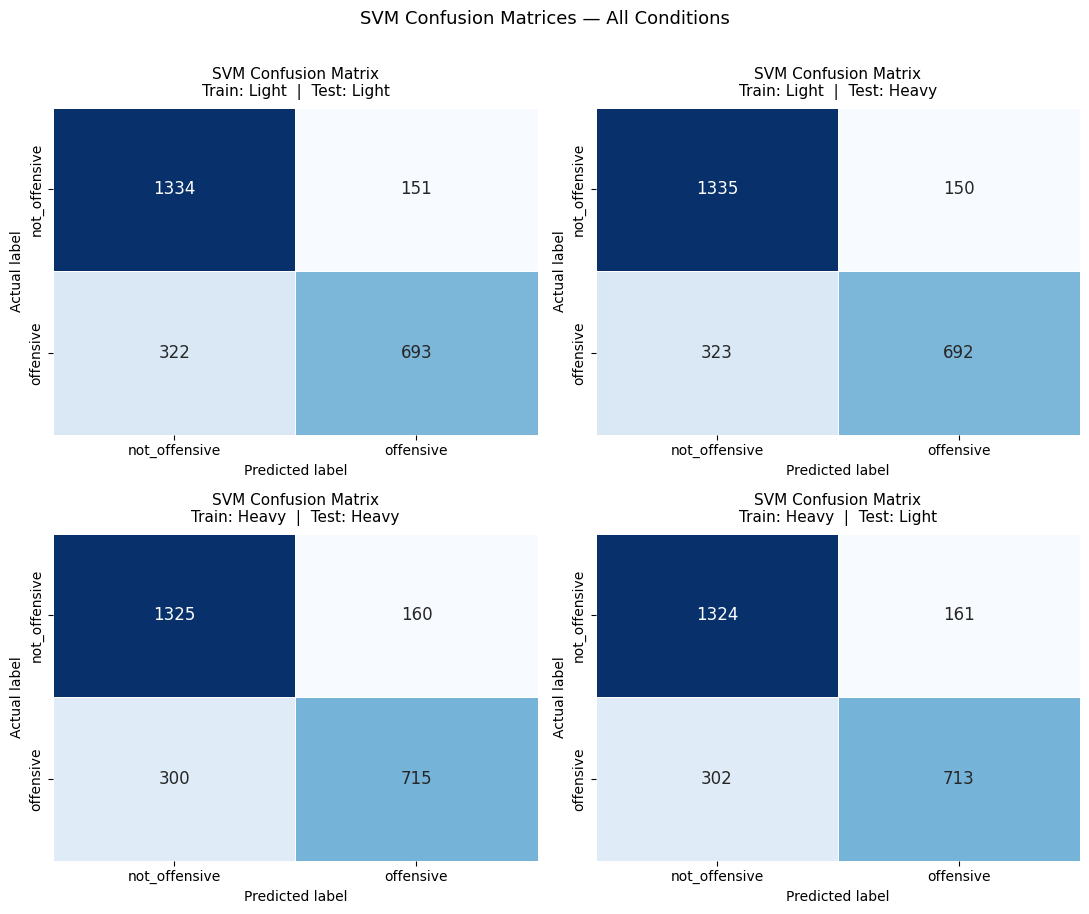

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (train_sev, test_sev) in zip(axes, EVAL_CONDITIONS):
    key = f"{train_sev}_train__{test_sev}_test"
    cm  = all_cms[key]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=ax,
        cbar=False,
        linewidths=0.5,
        annot_kws={"size": 12},
    )
    ax.set_title(
        f"SVM Confusion Matrix\nTrain: {train_sev.capitalize()}  |  Test: {test_sev.capitalize()}",
        fontsize=11, pad=8,
    )
    ax.set_xlabel("Predicted label", fontsize=10)
    ax.set_ylabel("Actual label", fontsize=10)

plt.suptitle("SVM Confusion Matrices — All Conditions", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


## 16. Performance / Degradation Analysis

Each trained model is evaluated on **both** test severities. The difference between a fixed model's
performance on the Light and Heavy test conditions provides an estimate of degradation associated with
increased code-mixing severity. Because the alignment check verifies that both test conditions contain
the same underlying source posts, this is a controlled comparison over the same evaluation items rather
than a comparison of unrelated samples.

This addresses the proposal's broader degradation objective (Section 5.4.2). However, the proposal defines
its main clean-to-noisy degradation as comparison against a clean baseline. Since the current assigned
experiment does not include clean SOLD, the present notebook reports **Light-test → Heavy-test degradation**
for each fixed SVM and does not label it as the final clean-to-noisy degradation result.


In [16]:
results_df = pd.DataFrame(all_results)

metrics = ["accuracy", "macro_f1", "weighted_f1", "recall_offensive", "recall_not_offensive"]
metric_labels = {
    "accuracy":            "Accuracy",
    "macro_f1":            "Macro-F1",
    "weighted_f1":         "Weighted-F1",
    "recall_offensive":    "Offensive Recall",
    "recall_not_offensive":"Not-Offensive Recall",
}

print("Degradation Table: Light-Test → Heavy-Test per fixed model")
print("(Drop = Light-Test metric − Heavy-Test metric; positive = heavier noise is harder)")
print()
print(f"{'Model':<16s} {'Metric':<22s} {'Light-Test':>12s} {'Heavy-Test':>12s} {'Drop':>10s}")
print("-" * 74)

for train_sev in SEVERITIES:
    r_light = results_df[
        (results_df.training_severity == train_sev) &
        (results_df.testing_severity  == "light")
    ].iloc[0]
    r_heavy = results_df[
        (results_df.training_severity == train_sev) &
        (results_df.testing_severity  == "heavy")
    ].iloc[0]

    for m in metrics:
        drop = r_light[m] - r_heavy[m]
        print(f"SVM-{train_sev:<11s} {metric_labels[m]:<22s} "
              f"{r_light[m]:12.4f} {r_heavy[m]:12.4f} {drop:+10.4f}")
    print()


Degradation Table: Light-Test → Heavy-Test per fixed model
(Drop = Light-Test metric − Heavy-Test metric; positive = heavier noise is harder)

Model            Metric                   Light-Test   Heavy-Test       Drop
--------------------------------------------------------------------------
SVM-light       Accuracy                     0.8108       0.8108    +0.0000
SVM-light       Macro-F1                     0.7975       0.7974    +0.0001
SVM-light       Weighted-F1                  0.8072       0.8072    +0.0001
SVM-light       Offensive Recall             0.6828       0.6818    +0.0010
SVM-light       Not-Offensive Recall         0.8983       0.8990    -0.0007

SVM-heavy       Accuracy                     0.8148       0.8160    -0.0012
SVM-heavy       Macro-F1                     0.8030       0.8044    -0.0013
SVM-heavy       Weighted-F1                  0.8121       0.8133    -0.0012
SVM-heavy       Offensive Recall             0.7025       0.7044    -0.0020
SVM-heavy       Not-

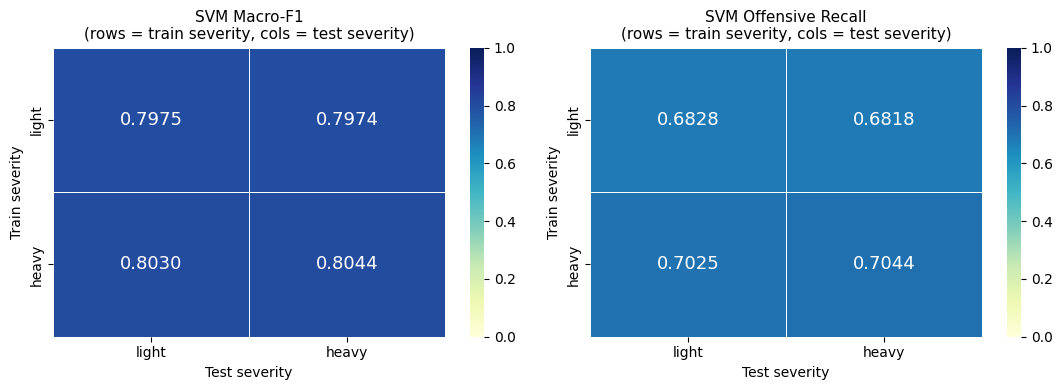

In [17]:
# ── Visualisation: Macro-F1 heatmap ─────────────────────────────────────────
pivot_macro = results_df.pivot(
    index="training_severity", columns="testing_severity", values="macro_f1"
).reindex(index=SEVERITIES, columns=SEVERITIES)

pivot_recall = results_df.pivot(
    index="training_severity", columns="testing_severity", values="recall_offensive"
).reindex(index=SEVERITIES, columns=SEVERITIES)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pivot, title, fmt in [
    (axes[0], pivot_macro,  "Macro-F1",         ".4f"),
    (axes[1], pivot_recall, "Offensive Recall",  ".4f"),
]:
    sns.heatmap(
        pivot,
        annot=True,
        fmt=fmt,
        cmap="YlGnBu",
        vmin=0, vmax=1,
        ax=ax,
        linewidths=0.5,
        annot_kws={"size": 13},
    )
    ax.set_title(f"SVM {title}\n(rows = train severity, cols = test severity)",
                 fontsize=11)
    ax.set_xlabel("Test severity")
    ax.set_ylabel("Train severity")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/performance_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()


## 17. Offensive-Class Recall Analysis

This section isolates offensive vs not-offensive recall across all conditions.


In [18]:
print("Offensive-Class Analysis\n")
print(f"{'Train':8s} {'Test':8s} {'Off. Prec':>11s} {'Off. Rec':>10s} {'Off. F1':>9s} "
      f"{'Not-Off. Rec':>14s} {'Rec Diff':>10s}")
print("-" * 75)

for _, r in results_df.iterrows():
    rec_diff = r["recall_offensive"] - r["recall_not_offensive"]
    print(f"{r['training_severity']:8s} {r['testing_severity']:8s} "
          f"{r['precision_offensive']:11.4f} {r['recall_offensive']:10.4f} "
          f"{r['f1_offensive']:9.4f} {r['recall_not_offensive']:14.4f} "
          f"{rec_diff:+10.4f}")

print()
print("Rec Diff = Offensive Recall − Not-Offensive Recall")
print("Negative values → noise hurts offensive detection disproportionately.")


Offensive-Class Analysis

Train    Test       Off. Prec   Off. Rec   Off. F1   Not-Off. Rec   Rec Diff
---------------------------------------------------------------------------
light    light         0.8211     0.6828    0.7456         0.8983    -0.2156
light    heavy         0.8219     0.6818    0.7453         0.8990    -0.2172
heavy    heavy         0.8171     0.7044    0.7566         0.8923    -0.1878
heavy    light         0.8158     0.7025    0.7549         0.8916    -0.1891

Rec Diff = Offensive Recall − Not-Offensive Recall
Negative values → noise hurts offensive detection disproportionately.


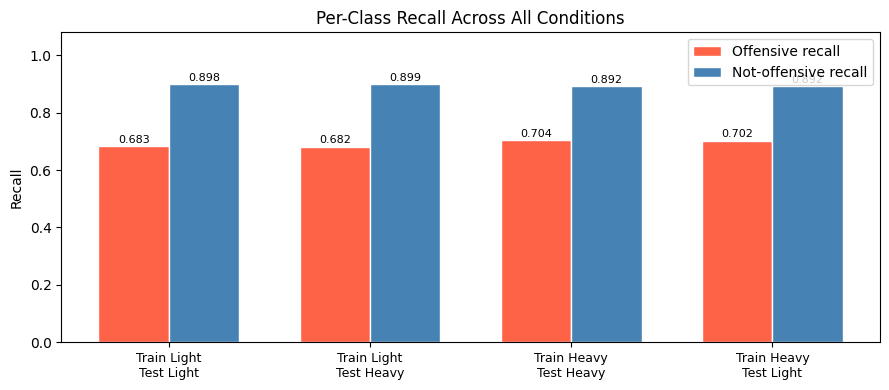

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))

x = np.arange(4)
w = 0.35
labels = [
    f"Train {r['training_severity'].capitalize()}\nTest {r['testing_severity'].capitalize()}"
    for _, r in results_df.iterrows()
]

bars1 = ax.bar(x - w/2, results_df["recall_offensive"],     width=w,
               color="tomato",    label="Offensive recall",     edgecolor="white")
bars2 = ax.bar(x + w/2, results_df["recall_not_offensive"], width=w,
               color="steelblue", label="Not-offensive recall", edgecolor="white")

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.08)
ax.set_title("Per-Class Recall Across All Conditions", fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/offensive_recall_analysis.png", dpi=150, bbox_inches="tight")
plt.show()


## 18. Error Analysis

For each evaluation condition, we examine:

- **False Negatives (FN):** Offensive posts the model missed (actual=1, predicted=0) — the most harmful error type.
- **False Positives (FP):** Not-offensive posts incorrectly flagged (actual=0, predicted=1).

Borderline errors (decision score closest to 0) are shown first, as these are the
most informative cases for understanding model weaknesses.



In [20]:
def show_errors(preds_df: pd.DataFrame,
                train_sev: str,
                test_sev: str,
                n: int = 10) -> None:
    """Display false-negative and false-positive examples for one eval condition."""

    print(f"\n{'='*70}")
    print(f"  Error Analysis — Train: {train_sev.upper()}  Test: {test_sev.upper()}")
    print(f"{'='*70}")

    # False Negatives: missed offensive content
    fn = preds_df[
        (preds_df["actual_label"] == 1) & (preds_df["predicted_label"] == 0)
    ].copy()
    fn["abs_decision_score"] = fn["decision_score"].abs()
    fn = fn.sort_values("abs_decision_score", ascending=True)  # closest to boundary first

    print(f"\nFALSE NEGATIVES (actual=offensive, predicted=not_offensive) — {len(fn):,} total")
    print(f"Showing {min(n, len(fn))} examples sorted by decision score (closest to boundary first):\n")
    for _, row in fn.head(n).iterrows():
        print(f"  text: {str(row[TEXT_COL])[:120]}")
        print(f"  decision_score: {row['decision_score']:.4f}")
        print()

    # False Positives: not-offensive flagged
    fp = preds_df[
        (preds_df["actual_label"] == 0) & (preds_df["predicted_label"] == 1)
    ].copy()
    fp["abs_decision_score"] = fp["decision_score"].abs()
    fp = fp.sort_values("abs_decision_score", ascending=True)

    print(f"FALSE POSITIVES (actual=not_offensive, predicted=offensive) — {len(fp):,} total")
    print(f"Showing {min(n, len(fp))} examples sorted by decision score (highest first):\n")
    for _, row in fp.head(n).iterrows():
        print(f"  text: {str(row[TEXT_COL])[:120]}")
        print(f"  decision_score: {row['decision_score']:.4f}")
        print()


for train_sev, test_sev in EVAL_CONDITIONS:
    key = f"{train_sev}_train__{test_sev}_test"
    show_errors(all_preds[key], train_sev, test_sev, n=5)



  Error Analysis — Train: LIGHT  Test: LIGHT

FALSE NEGATIVES (actual=offensive, predicted=not_offensive) — 322 total
Showing 5 examples sorted by decision score (closest to boundary first):

  text: @USER  @USER කේසර පලයන් අවුස්සන්නැතුව
  decision_score: -0.0023

  text: ලංකාවෙ ගොඩක් උන් බටහිර පන්නෙට ඉන්න හදන්නෙ  Sex වලදියි  Drugs වලදියි විතරයි    එත් උන්ගෙ thinking pattern එක හෙන ගොං awes
  decision_score: -0.0040

  text: @USER අද ඊයේ නෙවේ මූට පට්ට මානසික ලෙඩක් තියෙන්නේ රිපොට් කරපු තරමට මූ හැදුන නම් ආයේ එන්නෑ .ලිපිනය find කරන් මෑන් මානසික ද
  decision_score: -0.0048

  text: @USER ඔකුන් නිසා children කියක් තාත්ත නැතුව  බඩගින්නෙ ඉන්න අැත්ද..  හිටිය කියල වැඩක් නැනේ බඩ ගින්නේ මැරුනට පවු නැ ඔකුන් 
  decision_score: -0.0059

  text: මේ ලබ්බෙ Netflix ඇඩ් very වදයක් නෙහ් ඕයි  ඒකත් ඉන්දියන් එකක ඇඩ් එකක්.
  decision_score: -0.0060

FALSE POSITIVES (actual=not_offensive, predicted=offensive) — 151 total
Showing 5 examples sorted by decision score (highest first):

  text: twitter එක හරි යද්ද

## 19. Linear SVM Feature Analysis

If the best kernel is **linear**, we can inspect `coef_` to identify which character
n-grams most strongly predict each class.

**Interpretation caution:** The model may have learned code-mixing patterns,
character fragments, or punctuation sequences — not necessarily explicit hate speech
words. The features reflect what the character n-gram distribution captures in this data.

If the best kernel is **RBF**, no coefficient-based interpretation is available for that model.


In [21]:
def analyze_linear_features(artifact: dict, top_n: int = 20) -> None:
    """Show top character n-grams for each class if the SVM uses a linear kernel."""
    sev       = artifact["severity"]
    best_kernel = artifact["best_params"].get("svm__kernel", "unknown")

    print(f"\n{'='*70}")
    print(f"  Feature Analysis — SVM-{sev.upper()}   kernel={best_kernel}")
    print(f"{'='*70}")

    if best_kernel != "linear":
        print(
            "Coefficient-based feature analysis is only available for the linear SVM.\n"
            f"The best model for '{sev}' uses kernel='{best_kernel}'. Skipping."
        )
        return

    pipeline = artifact["pipeline"]
    coef     = pipeline.named_steps["svm"].coef_[0].toarray().flatten() # Convert to dense 1D array
    feature_names = pipeline.named_steps["tfidf"].get_feature_names_out()

    top_pos_idx = np.argsort(coef)[-top_n:][::-1]   # highest → class 1 (offensive)
    top_neg_idx = np.argsort(coef)[:top_n]           # lowest  → class 0 (not_offensive)

    print(f"\nTop {top_n} character n-grams → offensive (class 1):")
    for idx in top_pos_idx:
        print(f"  {feature_names[idx]!r:30s}  coef = {coef[idx]:+.4f}")

    print(f"\nTop {top_n} character n-grams → not_offensive (class 0):")
    for idx in top_neg_idx:
        print(f"  {feature_names[idx]!r:30s}  coef = {coef[idx]:+.4f}")


for sev in SEVERITIES:
    analyze_linear_features(trained_models[sev], top_n=20)



  Feature Analysis — SVM-LIGHT   kernel=rbf
Coefficient-based feature analysis is only available for the linear SVM.
The best model for 'light' uses kernel='rbf'. Skipping.

  Feature Analysis — SVM-HEAVY   kernel=rbf
Coefficient-based feature analysis is only available for the linear SVM.
The best model for 'heavy' uses kernel='rbf'. Skipping.


## 20. Save Model Pipelines

The complete Pipeline (TF-IDF + SVM) is saved for each severity. This means the saved
model can be loaded and used on raw text without separately reconstructing the vectorizer.

```python
# Loading later:
import joblib
pipeline = joblib.load("svm_pipeline_light.joblib")
preds = pipeline.predict(["some raw code-mixed text"])
```


In [22]:
for sev in SEVERITIES:
    model_path = f"{OUT_DIR}/svm_pipeline_{sev}.joblib"
    joblib.dump(trained_models[sev]["pipeline"], model_path)
    print(f"Saved: {model_path}")


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_pipeline_light.joblib
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_pipeline_heavy.joblib


## 21. Save Test Predictions

One CSV per evaluation condition. Each row contains the original text, actual label,
predicted label, correctness flag, and decision score.


In [23]:
for (train_sev, test_sev) in EVAL_CONDITIONS:
    key  = f"{train_sev}_train__{test_sev}_test"
    path = f"{OUT_DIR}/svm_predictions_{key}.csv"
    all_preds[key].to_csv(path, index=False, encoding="utf-8")
    print(f"Saved: {path}  ({len(all_preds[key]):,} rows)")


Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_predictions_light_train__light_test.csv  (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_predictions_light_train__heavy_test.csv  (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_predictions_heavy_train__heavy_test.csv  (2,500 rows)
Saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_predictions_heavy_train__light_test.csv  (2,500 rows)


## 22. Save Results and Model Metadata


In [24]:
# Save master results CSV
results_csv_path = f"{OUT_DIR}/svm_code-mixing_results.csv"
results_df.to_csv(results_csv_path, index=False, encoding="utf-8")
print("Results saved:", results_csv_path)

# Save metadata per model
import json as _json

for sev in SEVERITIES:
    art = trained_models[sev]
    pipeline = art["pipeline"]
    tfidf_params = pipeline.named_steps["tfidf"].get_params()
    svm_params   = pipeline.named_steps["svm"].get_params()

    meta = {
        "training_severity":  sev,
        "feature_representation": "character TF-IDF",
        "analyzer":           tfidf_params.get("analyzer"),
        "ngram_range":        str(tfidf_params.get("ngram_range")),
        "min_df":             tfidf_params.get("min_df"),
        "sublinear_tf":       tfidf_params.get("sublinear_tf"),
        "svm_kernel":         art["best_params"].get("svm__kernel"),
        "svm_C":              art["best_params"].get("svm__C"),
        "class_weight":       svm_params.get("class_weight"),
        "cv_folds":           5,
        "cv_scoring":         "f1_macro",
        "best_cv_macro_f1":   round(art["cv_macro_f1"], 6),
        "random_state":       RANDOM_STATE,
        "train_size":         art["train_size"],
        "majority_class":     int(pd.Series(data[sev]["train"][LABEL_COL]).mode().iloc[0]),
        "timestamp":          art["timestamp"],
    }
    meta_path = f"{OUT_DIR}/svm_metadata_{sev}.json"
    with open(meta_path, "w", encoding="utf-8") as f:
        _json.dump(meta, f, indent=2)
    print(f"Metadata saved: {meta_path}")


Results saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_code-mixing_results.csv
Metadata saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_metadata_light.json
Metadata saved: /content/drive/MyDrive/Sinhala-Noisy-Hatespeech-Data/svm_artifacts/codemix/svm_metadata_heavy.json


## 22.1. Verification Report

This report summarizes the methodological checks and actual experimental outputs after the notebook has run.


In [25]:
print("=" * 70)
print("  FINAL VERIFICATION REPORT — SVM CodeMix")
print("=" * 70)
print(f"CodeMix test alignment : VERIFIED ({len(aligned_test_ids):,} paired test posts)")
print()
for sev in SEVERITIES:
    art = trained_models[sev]
    print(f"SVM-{sev.upper()}")
    print(f"  Best parameters : {art['best_params']}")
    print(f"  CV Macro-F1     : {art['cv_macro_f1']:.4f}")
print()
print("Four test conditions:")
for _, r in results_df.iterrows():
    print(
        f"  {r['training_severity'].capitalize()} → {r['testing_severity'].capitalize()} | "
        f"Macro-F1={r['macro_f1']:.4f} | "
        f"Offensive Recall={r['recall_offensive']:.4f}"
    )
print()
print("Baseline checks:")
for _, r in results_df.iterrows():
    print(
        f"  {r['training_severity'].capitalize()} → {r['testing_severity'].capitalize()} | "
        f"Majority={r['majority_baseline_macro_f1']:.4f} | "
        f"Minority={r['minority_baseline_macro_f1']:.4f}"
    )
print()
print("Remaining methodological scope:")
print("  - This notebook covers code-mixing Light/Heavy only.")
print("  - Clean SOLD, other noise types, and multi-seed averaging are not included in this current experiment.")
print("  - The proposal's eventual clean-vs-noisy degradation analysis requires the clean SOLD baseline when that experiment is performed.")


  FINAL VERIFICATION REPORT — SVM CodeMix
CodeMix test alignment : VERIFIED (2,500 paired test posts)

SVM-LIGHT
  Best parameters : {'svm__C': 10, 'svm__kernel': 'rbf'}
  CV Macro-F1     : 0.8053
SVM-HEAVY
  Best parameters : {'svm__C': 10, 'svm__kernel': 'rbf'}
  CV Macro-F1     : 0.8040

Four test conditions:
  Light → Light | Macro-F1=0.7975 | Offensive Recall=0.6828
  Light → Heavy | Macro-F1=0.7974 | Offensive Recall=0.6818
  Heavy → Heavy | Macro-F1=0.8044 | Offensive Recall=0.7044
  Heavy → Light | Macro-F1=0.8030 | Offensive Recall=0.7025

Baseline checks:
  Light → Light | Majority=0.3726 | Minority=0.2888
  Light → Heavy | Majority=0.3726 | Minority=0.2888
  Heavy → Heavy | Majority=0.3726 | Minority=0.2888
  Heavy → Light | Majority=0.3726 | Minority=0.2888

Remaining methodological scope:
  - This notebook covers code-mixing Light/Heavy only.
  - Clean SOLD, other noise types, and multi-seed averaging are not included in this current experiment.
  - The proposal's eventual

## 23. Final Results Summary Tables


In [26]:
# Table 1: Core metrics
print("=== TABLE 1: Core Metrics ===\n")
t1_cols = [
    "training_severity", "testing_severity",
    "accuracy", "macro_f1", "weighted_f1",
    "majority_baseline_macro_f1", "minority_baseline_macro_f1",
    "beats_majority_baseline", "beats_minority_baseline",
]
print(results_df[t1_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print()

# Table 2: Per-class metrics
print("=== TABLE 2: Per-Class Metrics ===\n")
t2_cols = [
    "training_severity", "testing_severity",
    "precision_not_offensive", "recall_not_offensive", "f1_not_offensive",
    "precision_offensive",     "recall_offensive",     "f1_offensive",
    "support_not_offensive",   "support_offensive",
]
print(results_df[t2_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))


=== TABLE 1: Core Metrics ===

training_severity testing_severity  accuracy  macro_f1  weighted_f1  majority_baseline_macro_f1  minority_baseline_macro_f1  beats_majority_baseline  beats_minority_baseline
            light            light    0.8108    0.7975       0.8072                      0.3726                      0.2888                     True                     True
            light            heavy    0.8108    0.7974       0.8072                      0.3726                      0.2888                     True                     True
            heavy            heavy    0.8160    0.8044       0.8133                      0.3726                      0.2888                     True                     True
            heavy            light    0.8148    0.8030       0.8121                      0.3726                      0.2888                     True                     True

=== TABLE 2: Per-Class Metrics ===

training_severity testing_severity  precision_not_offensive  r

## 24. Research Interpretation / Conclusions

This section generates an automatic narrative from the actual results.

In [27]:
def auto_interpret(results_df: pd.DataFrame, trained_models: dict) -> None:
    """Generate a concise, data-driven summary of the CodeMix SVM experiment."""

    def get(train_sev, test_sev, col):
        return results_df[
            (results_df.training_severity == train_sev) &
            (results_df.testing_severity  == test_sev)
        ][col].values[0]

    print("=" * 70)
    print("  RESEARCH INTERPRETATION — SVM CodeMix Baseline")
    print("=" * 70)

    print()
    print("1. BEST HYPERPARAMETERS")
    for sev in SEVERITIES:
        art = trained_models[sev]
        print(f"   SVM-{sev.capitalize()}: {art['best_params']}  "
              f"(CV macro-F1 = {art['cv_macro_f1']:.4f})")

    print()
    print("2. SAME-SEVERITY PERFORMANCE")
    for sev in SEVERITIES:
        mf1 = get(sev, sev, "macro_f1")
        rec = get(sev, sev, "recall_offensive")
        print(f"   SVM-{sev.capitalize()} on {sev.capitalize()} CodeMix test: "
              f"Macro-F1 = {mf1:.4f},  Offensive Recall = {rec:.4f}")

    print()
    print("3. CROSS-SEVERITY GENERALISATION")
    for train_sev, test_sev in [("light", "heavy"), ("heavy", "light")]:
        mf1 = get(train_sev, test_sev, "macro_f1")
        rec = get(train_sev, test_sev, "recall_offensive")
        print(f"   SVM-{train_sev.capitalize()} → {test_sev.capitalize()} CodeMix test: "
              f"Macro-F1 = {mf1:.4f},  Offensive Recall = {rec:.4f}")

    print()
    print("4. SEVERITY DIFFERENCE (Light-test → Heavy-test, per fixed model)")
    print("   The CodeMix Light/Heavy test-set alignment was verified by source_id, "
          "so these are controlled comparisons over the same underlying posts.")
    for sev in SEVERITIES:
        drop_mf1 = get(sev, "light", "macro_f1") - get(sev, "heavy", "macro_f1")
        drop_rec = get(sev, "light", "recall_offensive") - get(sev, "heavy", "recall_offensive")
        direction = "harder" if drop_mf1 > 0 else "easier (or no degradation)"
        print(f"   SVM-{sev.capitalize()}: Macro-F1 change = {drop_mf1:+.4f}  "
              f"(Heavy test is {direction})")
        print(f"                 Offensive Recall change = {drop_rec:+.4f}")

    print()
    print("5. MAJORITY-CLASS BASELINE COMPARISON")
    all_beat = all(r["beats_majority_baseline"] for _, r in results_df.iterrows())
    print(f"   SVM beats majority-class baseline in ALL conditions: {all_beat}")
    for _, r in results_df.iterrows():
        gap = r["macro_f1"] - r["majority_baseline_macro_f1"]
        print(f"   Train={r['training_severity']} Test={r['testing_severity']}: "
              f"SVM {r['macro_f1']:.4f} vs majority baseline {r['majority_baseline_macro_f1']:.4f} "
              f"(gap = {gap:+.4f})")

    print()
    print("6. CLASS-SYMMETRY OF NOISE IMPACT")
    print("   (Offensive recall − Not-offensive recall; negative = offensive harder to detect)")
    for _, r in results_df.iterrows():
        diff = r["recall_offensive"] - r["recall_not_offensive"]
        print(f"   Train={r['training_severity']} Test={r['testing_severity']}: "
              f"diff = {diff:+.4f}")

    print()
    print("7. NEXT STEPS")
    print("   - Extend to the remaining noise types required by the project")
    print("   - Compare against encoder baselines under the same CodeMix conditions")
    print("   - Multi-seed evaluation (seeds: [42, 52, 62, 72, 82]) for variance reporting")
    print("   - Compare CodeMix robustness with the corresponding transliteration experiment")
    print("   - Use the SVM as the traditional ML reference for later ensemble experiments")


auto_interpret(results_df, trained_models)


  RESEARCH INTERPRETATION — SVM CodeMix Baseline

1. BEST HYPERPARAMETERS
   SVM-Light: {'svm__C': 10, 'svm__kernel': 'rbf'}  (CV macro-F1 = 0.8053)
   SVM-Heavy: {'svm__C': 10, 'svm__kernel': 'rbf'}  (CV macro-F1 = 0.8040)

2. SAME-SEVERITY PERFORMANCE
   SVM-Light on Light CodeMix test: Macro-F1 = 0.7975,  Offensive Recall = 0.6828
   SVM-Heavy on Heavy CodeMix test: Macro-F1 = 0.8044,  Offensive Recall = 0.7044

3. CROSS-SEVERITY GENERALISATION
   SVM-Light → Heavy CodeMix test: Macro-F1 = 0.7974,  Offensive Recall = 0.6818
   SVM-Heavy → Light CodeMix test: Macro-F1 = 0.8030,  Offensive Recall = 0.7025

4. SEVERITY DIFFERENCE (Light-test → Heavy-test, per fixed model)
   The CodeMix Light/Heavy test-set alignment was verified by source_id, so these are controlled comparisons over the same underlying posts.
   SVM-Light: Macro-F1 change = +0.0001  (Heavy test is harder)
                 Offensive Recall change = +0.0010
   SVM-Heavy: Macro-F1 change = -0.0013  (Heavy test is easier 

## Final Methodology Note — RBF-Enabled CodeMix Experiment

This notebook applies the refined SVM workflow to the **CodeMix Light/Heavy datasets**.

1. **Kernel tuning:** both `linear` and `rbf` SVM kernels are evaluated with `C ∈ {0.1, 1, 3, 10}` using 5-fold stratified CV and macro-F1.
2. **Source-ID leakage validation:** all CodeMix train/test severity combinations are checked for overlapping `source_id` values before training. Any overlap stops the experiment.
3. **Cross-severity evaluation:** CodeMix Light-trained and Heavy-trained models are each evaluated on both CodeMix test severities.
4. **Artifact isolation:** all CodeMix models, predictions, results, and metadata are saved under a dedicated `svm_artifacts/codemix` directory so the transliteration experiment is not overwritten.

The underlying SVM methodology remains the same as the refined transliteration baseline: character TF-IDF with 1–5 character n-grams, balanced class weighting, 5-fold stratified CV, automatic Linear/RBF selection, Macro-F1 model selection, four cross-severity evaluations, and the same evaluation/analysis framework.


## Final Scope and Methodology

This notebook is the SVM baseline for the **CodeMix Light/Heavy experiment**.

- CodeMix Light and Heavy datasets are loaded from the same `outputs/train` and `outputs/test` directories used by the other noise experiments.
- Character-level TF-IDF with `char_wb` and 1–5 character n-grams is used as the primary representation.
- TF-IDF remains inside the SVM pipeline and therefore inside each CV fold.
- `class_weight="balanced"` handles the class imbalance during SVM training.
- `GridSearchCV` automatically evaluates both `linear` and `rbf` kernels with `C ∈ {0.1, 1, 3, 10}` using 5-fold stratified CV and macro-F1.
- The test sets are not used for model selection.
- CodeMix Light and Heavy models are trained separately.
- All four train/test severity combinations are evaluated.
- CodeMix Light/Heavy test alignment is checked by `source_id` before paired severity comparisons.
- Train/test `source_id` overlap is checked across all severity combinations before training.
- If the selected model is linear, coefficient-based feature analysis is performed; if RBF is selected, coefficient-based analysis is skipped because RBF does not provide the same linear coefficient interpretation.
- Clean SOLD and other noise types are outside this current CodeMix experiment.
- Multi-seed averaging can be added later if required for the final project-wide benchmark.
